<a href="https://colab.research.google.com/github/Anyangos/Digital-Twin/blob/RAG/Week2_06_string_surgery_text_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Advanced 1: String Surgery - Text Processing for Digital Twins

## Learning Objectives
- Master Python string manipulation techniques
- Learn text cleaning and preprocessing for RAG systems
- Build robust text processing pipelines
- Debug and slice text effectively

## Key Insight
> **(Logic Bridge) Before using LangChain, learn to manually split() text. If you can't slice a string, you can't debug RAG.**

## Digital Twin Context
Your digital twin needs to process messy, real-world text:
- User messages with typos and inconsistent formatting
- Documents from various sources (PDFs, emails, chats)
- Structured data extraction from unstructured text
- Context preparation for LLM consumption

This is the **foundation** for building RAG systems!

In [2]:
# Import required libraries
import re
import string
from typing import List, Dict, Tuple
from collections import Counter
import json

print("✅ String surgery tools loaded!")
print("\n🔧 Available string methods:")
print([m for m in dir(str) if not m.startswith('_')][:15], "...")

✅ String surgery tools loaded!

🔧 Available string methods:
['capitalize', 'casefold', 'center', 'count', 'encode', 'endswith', 'expandtabs', 'find', 'format', 'format_map', 'index', 'isalnum', 'isalpha', 'isascii', 'isdecimal'] ...


---
## Part 1: Basic String Operations - The Fundamentals

Before building complex systems, master the basics!

### 1.1 String Slicing and Indexing

In [3]:
# Digital twin user message
user_message = "Hello! I love running at 6am every morning. Coffee is essential."

print("Original message:")
print(f"  '{user_message}'")
print(f"  Length: {len(user_message)} characters")

# Basic indexing
print("\n📍 Indexing:")
print(f"  First character: '{user_message[0]}'")
print(f"  Last character: '{user_message[-1]}'")
print(f"  Character at position 10: '{user_message[10]}'")

# Slicing
print("\n✂️ Slicing:")
print(f"  First 5 characters: '{user_message[:5]}'")
print(f"  Last 10 characters: '{user_message[-10:]}'")
print(f"  Middle section (7-20): '{user_message[7:20]}'")
print(f"  Every 2nd character: '{user_message[::2]}'")
print(f"  Reversed: '{user_message[::-1]}'")

Original message:
  'Hello! I love running at 6am every morning. Coffee is essential.'
  Length: 64 characters

📍 Indexing:
  First character: 'H'
  Last character: '.'
  Character at position 10: 'o'

✂️ Slicing:
  First 5 characters: 'Hello'
  Last 10 characters: 'essential.'
  Middle section (7-20): 'I love runnin'
  Every 2nd character: 'Hlo  oerniga a vr onn.Cfe sesnil'
  Reversed: '.laitnesse si eeffoC .gninrom yreve ma6 ta gninnur evol I !olleH'


### 🎯 Exercise 1.1 (Easy): String Extraction

**Task**: Extract specific information from a digital twin log entry.

Given: `"2026-01-13 14:30:00 | USER_123 | Activity: Running | Duration: 45min"`

Extract:
1. The date (YYYY-MM-DD)
2. The time (HH:MM:SS)
3. The user ID
4. The activity
5. The duration

In [4]:
# YOUR CODE HERE
log_entry = "2026-01-13 14:30:00 | USER_123 | Activity: Running | Duration: 45min"

# Extract each component using slicing
date = log_entry[0:10]  # Example
time = log_entry[11:19]
user_id = log_entry[22:30]
activity = log_entry[42:51]
duration = log_entry[-5:]

# Verify your extraction
print(f"Date: {date}")
print(f"Time: {time}")
print(f"User ID: {user_id}")
print(f"Activity: {activity}")
print(f"Duration: {duration}")

Date: 2026-01-13
Time: 14:30:00
User ID: USER_123
Activity:  Running 
Duration: 45min


### 1.2 String Methods - Your Power Tools

In [5]:
# Messy user input (real-world scenario)
messy_input = "  I LOVE running, Coding AND   reading!!!  "

print("Original (messy):")
print(f"  '{messy_input}'")

# Cleaning operations
print("\n🧹 Cleaning operations:")

# Strip whitespace
cleaned = messy_input.strip()
print(f"  .strip(): '{cleaned}'")

# Case normalization
print(f"  .lower(): '{cleaned.lower()}'")
print(f"  .upper(): '{cleaned.upper()}'")
print(f"  .title(): '{cleaned.title()}'")

# Replace
print(f"  .replace('!', ''): '{cleaned.replace('!', '')}'")

# Split
words = cleaned.lower().replace('!', '').replace(',', '').split()
print(f"  .split(): {words}")

# Join
rejoined = " ".join(words)
print(f"  ' '.join(): '{rejoined}'")

Original (messy):
  '  I LOVE running, Coding AND   reading!!!  '

🧹 Cleaning operations:
  .strip(): 'I LOVE running, Coding AND   reading!!!'
  .lower(): 'i love running, coding and   reading!!!'
  .upper(): 'I LOVE RUNNING, CODING AND   READING!!!'
  .title(): 'I Love Running, Coding And   Reading!!!'
  .replace('!', ''): 'I LOVE running, Coding AND   reading'
  .split(): ['i', 'love', 'running', 'coding', 'and', 'reading']
  ' '.join(): 'i love running coding and reading'


### 1.3 Searching and Finding

In [6]:
text = "I love running at 6am. Running keeps me energized."

print("Text:", text)
print("\n🔍 Searching operations:")

# Find
print(f"  .find('running'): {text.find('running')}  # Position of first occurrence")
print(f"  .find('Running'): {text.find('Running')}")
print(f"  .find('swimming'): {text.find('swimming')}  # Returns -1 if not found")

# Count
print(f"\n  .count('running'): {text.count('running')}")
print(f"  .count('Running'): {text.count('Running')}")
print(f"  .lower().count('running'): {text.lower().count('running')}  # Case-insensitive")

# Boolean checks
print("\n  Boolean checks:")
print(f"    'running' in text: {'running' in text}")
print(f"    'Running' in text: {'Running' in text}")
print(f"    text.startswith('I love'): {text.startswith('I love')}")
print(f"    text.endswith('energized.'): {text.endswith('energized.')}")

Text: I love running at 6am. Running keeps me energized.

🔍 Searching operations:
  .find('running'): 7  # Position of first occurrence
  .find('Running'): 23
  .find('swimming'): -1  # Returns -1 if not found

  .count('running'): 1
  .count('Running'): 1
  .lower().count('running'): 2  # Case-insensitive

  Boolean checks:
    'running' in text: True
    'Running' in text: True
    text.startswith('I love'): True
    text.endswith('energized.'): True


### 🎯 Exercise 1.2 (Easy): Text Cleaning Pipeline

**Task**: Create a function to clean user input for the digital twin.

**Requirements**:
1. Remove extra whitespace
2. Convert to lowercase
3. Remove punctuation
4. Remove stop words (common words like 'the', 'a', 'is')

In [7]:
import re
def clean_text(text: str, remove_stopwords: bool = True) -> str:
    """
    Clean text for digital twin processing.

    Args:
        text: Input text
        remove_stopwords: Whether to remove common words

    Returns:
        str: Cleaned text
    """
    # Define stopwords
    stopwords = {'the', 'a', 'an', 'and', 'or', 'but', 'is', 'are', 'was', 'were',
                 'in', 'on', 'at', 'to', 'for', 'of', 'with', 'by'}

    # Step 1: Strip whitespace
    stripped = text.strip()

    # Step 2: Convert to lowercase
    lower = stripped.lower()

    # Step 3: Remove punctuation
    no_punc = re.sub(r"[^\w\s]", "",lower)

    # Step 4: Remove stopwords (if enabled)
    if stopwords:
      cleaned_words = no_punc.split()
      cleaned_words = [word for word in cleaned_words if word not in stopwords]
      cleaned = cleaned_words

    return cleaned

# Test your function
test_texts = [
    "  I LOVE running in the morning!  ",
    "The weather is perfect for outdoor activities.",
    "Coffee, coding, and creativity are my passions!!!"
]

for text in test_texts:
    cleaned = clean_text(text)
    print(f"Original: '{text}'")
    print(f"Cleaned:  '{cleaned}'")
    print()

Original: '  I LOVE running in the morning!  '
Cleaned:  '['i', 'love', 'running', 'morning']'

Original: 'The weather is perfect for outdoor activities.'
Cleaned:  '['weather', 'perfect', 'outdoor', 'activities']'

Original: 'Coffee, coding, and creativity are my passions!!!'
Cleaned:  '['coffee', 'coding', 'creativity', 'my', 'passions']'



---
## Part 2: Regular Expressions - Pattern Matching Power

When basic string methods aren't enough, regex is your weapon!

### 2.1 Regex Basics

In [8]:
# Digital twin conversation with multiple data types
conversation = """
User: My email is john.doe@email.com and I live at 123 Main St.
User: Call me at +1-555-123-4567 or text me!
User: I usually wake up at 6:30am and sleep by 10:45pm.
User: Check out my profile: https://example.com/profile/johndoe
"""

print("Conversation:")
print(conversation)
print("\n" + "="*60)

# Extract emails
email_pattern = r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b'
emails = re.findall(email_pattern, conversation)
print(f"\n📧 Emails found: {emails}")

# Extract phone numbers
phone_pattern = r'\+?\d{1,3}[-.]?\d{3}[-.]?\d{3}[-.]?\d{4}'
phones = re.findall(phone_pattern, conversation)
print(f"📱 Phone numbers found: {phones}")

# Extract times
time_pattern = r'\d{1,2}:\d{2}(?:am|pm)'
times = re.findall(time_pattern, conversation)
print(f"🕐 Times found: {times}")

# Extract URLs
url_pattern = r'https?://[^\s]+'
urls = re.findall(url_pattern, conversation)
print(f"🔗 URLs found: {urls}")

Conversation:

User: My email is john.doe@email.com and I live at 123 Main St.
User: Call me at +1-555-123-4567 or text me!
User: I usually wake up at 6:30am and sleep by 10:45pm.
User: Check out my profile: https://example.com/profile/johndoe



📧 Emails found: ['john.doe@email.com']
📱 Phone numbers found: ['+1-555-123-4567']
🕐 Times found: ['6:30am', '10:45pm']
🔗 URLs found: ['https://example.com/profile/johndoe']


### 2.2 Common Regex Patterns for Digital Twins

In [9]:
# Pattern library for digital twin data extraction
PATTERNS = {
    'email': r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b',
    'phone': r'\+?\d{1,3}[-.]?\d{3}[-.]?\d{3}[-.]?\d{4}',
    'date': r'\d{4}-\d{2}-\d{2}',
    'time': r'\d{1,2}:\d{2}(?::\d{2})?(?:am|pm)?',
    'url': r'https?://[^\s]+',
    'hashtag': r'#\w+',
    'mention': r'@\w+',
    'number': r'\b\d+(?:\.\d+)?\b',
    'duration': r'\d+(?:h|hr|hours?|m|min|minutes?|s|sec|seconds?)',
}

def extract_patterns(text: str, pattern_name: str) -> List[str]:
    """
    Extract all matches for a given pattern.

    Args:
        text: Input text
        pattern_name: Name of pattern from PATTERNS dict

    Returns:
        list: All matches
    """
    if pattern_name not in PATTERNS:
        raise ValueError(f"Unknown pattern: {pattern_name}")

    pattern = PATTERNS[pattern_name]
    return re.findall(pattern, text, re.IGNORECASE)

# Test with social media-like text
social_text = """
Just finished a 5km run in 30min! 🏃 #running #fitness
@FitnessCoach check out my progress at https://myapp.com/progress
Next goal: 10km in under 1hr. Training starts 2026-01-15 at 6:00am!
"""

print("Text:", social_text)
print("\n" + "="*60)
print("\nExtracted data:")

for pattern_name in ['number', 'duration', 'hashtag', 'mention', 'url', 'date', 'time']:
    matches = extract_patterns(social_text, pattern_name)
    if matches:
        print(f"  {pattern_name.title()}: {matches}")

Text: 
Just finished a 5km run in 30min! 🏃 #running #fitness
@FitnessCoach check out my progress at https://myapp.com/progress
Next goal: 10km in under 1hr. Training starts 2026-01-15 at 6:00am!



Extracted data:
  Number: ['2026', '01', '15', '6']
  Duration: ['30m', '1h']
  Hashtag: ['#running', '#fitness']
  Mention: ['@FitnessCoach']
  Url: ['https://myapp.com/progress']
  Date: ['2026-01-15']
  Time: ['6:00am']


### 🎯 Exercise 2.1 (Intermediate): Build a Personal Data Extractor

**Task**: Create a comprehensive data extraction system for digital twin profiles.

**Requirements**:
1. Extract all personal identifiers (email, phone, social handles)
2. Extract temporal information (dates, times, durations)
3. Extract preferences and activities from hashtags
4. Return structured data (dictionary)

In [10]:
import re
import json
from typing import Dict, Any

PATTERNS = {
    'email': r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b',
    'phone': r'\+?\d{1,3}[-.]?\d{3}[-.]?\d{3}[-.]?\d{4}',
    'date': r'\d{4}-\d{2}-\d{2}',
    'time': r'\d{1,2}:\d{2}(?::\d{2})?(?:am|pm)?',
    'url': r'https?://[^\s]+',
    'hashtag': r'#\w+',
    'mention': r'@\w+',
    'duration': r'\d+(?:h|hr|hours?|m|min|minutes?|s|sec|seconds?)',
    'age': r'\d+\s*(?:years?\s*old)',
    'distance': r'\d+\s*(?:km|miles|m)\b'
}

def extract_profile_data(text: str) -> Dict[str, Any]:
    """
    Extract structured data from user text.

    Args:
        text: User profile or conversation text

    Returns:
        dict: Extracted data organized by category
    """
    profile = {
        'contact': {},
        'temporal': {},
        'interests': [],
        'metrics': {},
    }
# if statement is used in order to avoid extracting raw values such as phone number when 'number' is called
    # 1. Extract contact information
    email_matches = extract_patterns(text, 'email')
    if email_matches:
        profile['contact']['emails'] = email_matches

    phone_matches = extract_patterns(text, 'phone')
    if phone_matches:
        profile['contact']['phone'] = phone_matches

    mention_matches = extract_patterns(text, 'mention')
    if mention_matches:
      profile['contact']['mention'] = mention_matches

    online_matches = extract_patterns(text, 'url')
    if online_matches:
      profile['contact']['url'] = online_matches

    # 2. Extract temporal data
    time_matches = extract_patterns(text, 'time')
    if time_matches:
        profile['temporal']['time'] = time_matches

    date_matches = extract_patterns(text, 'date')
    if date_matches:
        profile['temporal']['date'] = date_matches

    # 3. Extract interests from hashtags
    interest_matches = extract_patterns(text, 'hashtag')
    if interest_matches:
        profile['interests'] = interest_matches

    # 4. Extract metrics
    age_matches = extract_patterns(text, 'age')
    if age_matches:
        profile['metrics']['age'] = age_matches[0]

    distance_matches = extract_patterns(text, 'distance')
    if distance_matches:
        profile['metrics']['distances'] = distance_matches

    duration_matches = extract_patterns(text, 'duration')
    if duration_matches:
        profile['metrics']['durations'] = duration_matches

    return profile

# Test with comprehensive profile
test_profile = """
Hi! I'm Sarah (sarah.runner@email.com). Reach me at +1-555-234-5678.
I run 5km daily at 6:30am and love #running #fitness #health.
My best time: 25min for 5km. Goal: 10km in 50min by 2026-03-01.
Follow my journey: https://strava.com/sarah_runs and @SarahRuns on Twitter!
"""

extracted = extract_profile_data(test_profile)
print(json.dumps(extracted, indent=2))

{
  "contact": {
    "emails": [
      "sarah.runner@email.com"
    ],
    "phone": [
      "+1-555-234-5678"
    ],
    "mention": [
      "@email",
      "@SarahRuns"
    ],
    "url": [
      "https://strava.com/sarah_runs"
    ]
  },
  "temporal": {
    "time": [
      "6:30am"
    ],
    "date": [
      "2026-03-01"
    ]
  },
  "interests": [
    "#running",
    "#fitness",
    "#health"
  ],
  "metrics": {
    "distances": [
      "5km",
      "5km",
      "10km"
    ],
    "durations": [
      "25m",
      "50m"
    ]
  }
}


---
## Part 3: Text Chunking for RAG Systems

**Critical for RAG**: Breaking documents into optimal chunks for retrieval.

### 3.1 Simple Chunking Strategies

In [11]:
# Sample document about digital twin
long_document = """
A digital twin is a virtual representation of a physical object or system.
Digital twins are used across various industries. In healthcare, they model patient health.
In manufacturing, they simulate production processes. Smart cities use digital twins for urban planning.

The technology relies on real-time data from sensors. This data feeds into simulation models.
Machine learning algorithms analyze patterns. Predictions help optimize operations.

Benefits include improved decision-making. Companies reduce costs through predictive maintenance.
Healthcare providers personalize treatments. City planners optimize resource allocation.
"""

def chunk_by_sentences(text: str, sentences_per_chunk: int = 2) -> List[str]:
    """
    Chunk text by sentences.

    Args:
        text: Input text
        sentences_per_chunk: Number of sentences per chunk

    Returns:
        list: Text chunks
    """
    # Simple sentence splitting (not perfect, but educational)
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())

    chunks = []
    for i in range(0, len(sentences), sentences_per_chunk):
        chunk = ' '.join(sentences[i:i+sentences_per_chunk])
        chunks.append(chunk)

    return chunks

def chunk_by_words(text: str, words_per_chunk: int = 50, overlap: int = 10) -> List[str]:
    """
    Chunk text by word count with overlap.

    Args:
        text: Input text
        words_per_chunk: Target words per chunk
        overlap: Number of overlapping words

    Returns:
        list: Text chunks
    """
    words = text.split()
    chunks = []

    for i in range(0, len(words), words_per_chunk - overlap):
        chunk = ' '.join(words[i:i+words_per_chunk]) # this line does list slicing and string joining
        chunks.append(chunk)

        if i + words_per_chunk >= len(words):
            break

    return chunks

# Test chunking strategies
print("Original document length:", len(long_document), "characters")
print("\n" + "="*60)

# Sentence-based chunking
sentence_chunks = chunk_by_sentences(long_document, sentences_per_chunk=3)
print(f"\nSentence-based chunks ({len(sentence_chunks)} chunks):")
for i, chunk in enumerate(sentence_chunks, 1):
    print(f"\nChunk {i} ({len(chunk)} chars):")
    print(chunk[:100] + "..." if len(chunk) > 100 else chunk)

# Word-based chunking with overlap
print("\n" + "="*60)
word_chunks = chunk_by_words(long_document, words_per_chunk=30, overlap=5)
print(f"\nWord-based chunks ({len(word_chunks)} chunks, 30 words/chunk, 5 word overlap):")
for i, chunk in enumerate(word_chunks, 1):
    word_count = len(chunk.split())
    print(f"\nChunk {i} ({word_count} words):")
    print(chunk[:100] + "..." if len(chunk) > 100 else chunk)

Original document length: 640 characters


Sentence-based chunks (5 chunks):

Chunk 1 (166 chars):
A digital twin is a virtual representation of a physical object or system. Digital twins are used ac...

Chunk 2 (158 chars):
In manufacturing, they simulate production processes. Smart cities use digital twins for urban plann...

Chunk 3 (123 chars):
This data feeds into simulation models. Machine learning algorithms analyze patterns. Predictions he...

Chunk 4 (142 chars):
Benefits include improved decision-making. Companies reduce costs through predictive maintenance. He...

Chunk 5 (43 chars):
City planners optimize resource allocation.


Word-based chunks (4 chunks, 30 words/chunk, 5 word overlap):

Chunk 1 (30 words):
A digital twin is a virtual representation of a physical object or system. Digital twins are used ac...

Chunk 2 (30 words):
health. In manufacturing, they simulate production processes. Smart cities use digital twins for urb...

Chunk 3 (30 words):
feeds into simulati

chunk = ' '.join(words[i:i+words_per_chunk])

**Step 1: List Slicing (words[i:i+words_per_chunk])**

*words * is a list of individual words from our text (e.g., ['A', 'digital', 'twin', 'is', 'a', 'virtual', ...]).
[i:i+words_per_chunk] is a slice operation. It extracts a sub-list starting at index i up to (but not including) index i + words_per_chunk.

Example: If i = 0 and words_per_chunk = 3, this extracts a sub-list of the first 3 elements: ['A', 'digital', 'twin'].

**Step 2: String Joining (' '.join(...))**

When we slice the list, we get a smaller list of words: ['A', 'digital', 'twin'].
We cannot feed a raw list directly into an LLM or database as a coherent chunk; it needs to be a regular string.

' '.join(...) takes all elements in that sub-list and concatenates them together into one single string, inserting a space character (' ') between each word.

Example: ['A', 'digital', 'twin'] becomes the string

### 💡 Deep Dive: Understanding `kwargs.get()`

In Python, `**kwargs**` allows a function to accept any number of keyword arguments as a dictionary.

Using `.get()` on this dictionary is a best practice because:
1. **Avoids KeyErrors**: If a user doesn't provide a parameter (e.g., `overlap`), standard dictionary lookup `kwargs['overlap']` would throw a `KeyError`. `.get()` returns `None` instead.
2. **Provides Default Fallbacks**: We can provide a second argument, like `kwargs.get('overlap', 10)`, which acts as the default value if the user didn't specify that keyword.

In [1]:
def demo_kwargs_getter(**kwargs):
    # If 'max_chunk_size' isn't passed, fall back to 50
    max_chunk_size = kwargs.get('max_chunk_size', 50)
    # If 'overlap' isn't passed, fall back to 10
    overlap = kwargs.get('overlap', 10)

    print(f"Active Configuration -> Max Chunk Size: {max_chunk_size}, Overlap: {overlap}")

print("1. Calling with customized parameters:")
demo_kwargs_getter(max_chunk_size=100, overlap=25)

print("\n2. Calling with no parameters (relying on default values):")
demo_kwargs_getter()

1. Calling with customized parameters:
Active Configuration -> Max Chunk Size: 100, Overlap: 25

2. Calling with no parameters (relying on default values):
Active Configuration -> Max Chunk Size: 50, Overlap: 10


### 🔍 Understanding `kwargs` vs `**kwargs`

It is common to see `**kwargs` in Python function definitions, but it helps to break it down into two parts: the name (`kwargs`) and the unpacking operator (`**`).

#### 1. What is `kwargs`?
`kwargs` is short for **K**ey**W**ord **ARG**ument**S**.
* Inside your function, `kwargs` is just a standard Python **dictionary** (`dict`).
* Technically, you can name this dictionary anything you want (e.g., `**config` or `**options`). However, using `**kwargs` is a strong Python convention that makes your code immediately readable to other developers.

#### 2. What does the `**` (Double Asterisk) do?
The `**` is the **unpacking operator**. Its job changes depending on where you use it:

* **In a function parameter definition**: It tells Python to collect all extra, unnamed keyword arguments passed to the function and package them into a dictionary named `kwargs`.
* **In a function call**: It does the opposite. It unpacks a dictionary's key-value pairs directly into keyword arguments for the function.

In [12]:
# 1. Defining a function using ** to collect arguments into a dictionary (kwargs)
def print_user_profile(name, **kwargs):
    print(f"User: {name}")
    print(f"Type of kwargs: {type(kwargs)}")  # This will show it is a dictionary
    print(f"Contents of kwargs: {kwargs}\n")

# Call the function with keyword arguments
print_user_profile("Sarah", city="New York", job="Developer")

# 2. Using ** in a function call to unpack an existing dictionary
my_details = {"city": "Tokyo", "job": "Designer"}

# This is exactly equivalent to calling print_user_profile("Ken", city="Tokyo", job="Designer")
print_user_profile("Ken", **my_details)

User: Sarah
Type of kwargs: <class 'dict'>
Contents of kwargs: {'city': 'New York', 'job': 'Developer'}

User: Ken
Type of kwargs: <class 'dict'>
Contents of kwargs: {'city': 'Tokyo', 'job': 'Designer'}



### 3.2 Semantic Chunking (Advanced)

In [14]:
def chunk_by_paragraphs(text: str) -> List[str]:
    """
    Chunk text by paragraphs (natural semantic boundaries).

    Args:
        text: Input text

    Returns:
        list: Paragraph chunks
    """
    # Split on double newlines
    paragraphs = re.split(r'\n\s*\n', text.strip())
    # Clean each paragraph
    chunks = [p.strip() for p in paragraphs if p.strip()]
    return chunks

def smart_chunk(text: str,
                max_chunk_size: int = 200,
                overlap: int = 20) -> List[Dict[str, any]]:
    """
    Smart chunking that respects semantic boundaries.

    Args:
        text: Input text
        max_chunk_size: Maximum words per chunk
        overlap: Overlap words between chunks

    Returns:
        list: Chunks with metadata
    """
    # First, try to split by paragraphs
    paragraphs = chunk_by_paragraphs(text)

    chunks = []
    current_chunk = ""

    for para in paragraphs:
        para_words = len(para.split())
        current_words = len(current_chunk.split())

        # If adding paragraph exceeds limit, save current and start new
        if current_words + para_words > max_chunk_size and current_chunk:
            chunks.append({
                'text': current_chunk.strip(),
                'word_count': len(current_chunk.split()),
                'char_count': len(current_chunk)
            })

            # Start new chunk with overlap from previous
            words = current_chunk.split()
            overlap_text = ' '.join(words[-overlap:]) if len(words) > overlap else current_chunk
            current_chunk = overlap_text + ' ' + para
        else:
            current_chunk = current_chunk + '\n' + para if current_chunk else para

    # Add final chunk
    if current_chunk:
        chunks.append({
            'text': current_chunk.strip(),
            'word_count': len(current_chunk.split()),
            'char_count': len(current_chunk)
        })

    return chunks

# Test smart chunking
smart_chunks = smart_chunk(long_document, max_chunk_size=50, overlap=10)

print("Smart Chunking Results:")
print(f"Total chunks: {len(smart_chunks)}\n")

for i, chunk in enumerate(smart_chunks, 1):
    print(f"Chunk {i}:")
    print(f"  Words: {chunk['word_count']}, Chars: {chunk['char_count']}")
    print(f"  Text preview: {chunk['text'][:100]}...")
    print()

Smart Chunking Results:
Total chunks: 3

Chunk 1:
  Words: 40, Chars: 271
  Text preview: A digital twin is a virtual representation of a physical object or system.
Digital twins are used ac...

Chunk 2:
  Words: 33, Chars: 250
  Text preview: production processes. Smart cities use digital twins for urban planning. The technology relies on re...

Chunk 3:
  Words: 29, Chars: 278
  Text preview: models. Machine learning algorithms analyze patterns. Predictions help optimize operations. Benefits...



### 🎯 Exercise 3.1 (Advanced): Build a Chunking System

**Task**: Create a configurable chunking system for the digital twin's knowledge base.

**Requirements**:
1. Support multiple chunking strategies (sentence, word, paragraph, smart)
2. Add metadata to each chunk (position, source, timestamp)
3. Validate chunk quality (no orphaned sentences, reasonable size)
4. Create visualization of chunk distribution

Sample Chunk Metadatas:
Text: A digital twin is a virtual representation of a ph...
Metadata: {'position': '1/3', 'index': 0, 'source': 'knowledge_base_doc', 'timestamp': '2026-10-28 19:30:14'}

Text: Smart cities use digital twins for urban planning....
Metadata: {'position': '2/3', 'index': 1, 'source': 'knowledge_base_doc', 'timestamp': '2026-10-28 19:30:14'}

Text: learning algorithms analyze patterns. Predictions ...
Metadata: {'position': '3/3', 'index': 2, 'source': 'knowledge_base_doc', 'timestamp': '2026-10-28 19:30:14'}

Validation metrics: {'total_chunks': 3, 'valid_chunks': 3, 'invalid_chunks': 0, 'errors': []}


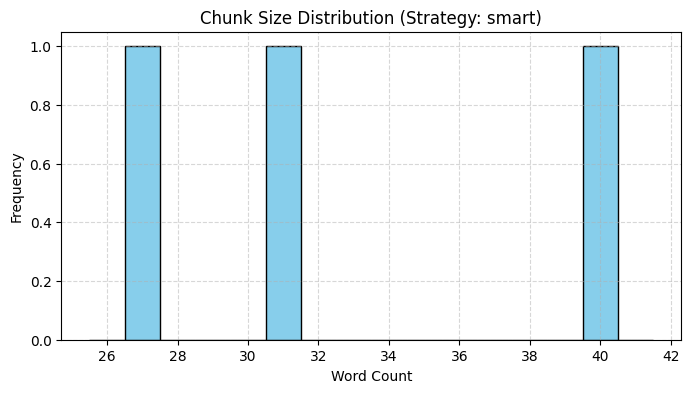

In [19]:
import matplotlib.pyplot as plt
import re
import time
from typing import List, Dict, Any

class ChunkingSystem:
    """
    Flexible chunking system for RAG preparation.
    Supports sentence, word, paragraph, and smart semantic boundary strategies.
    """

    def __init__(self, strategy: str = 'smart'):
        # Set the default chunking strategy
        self.strategy = strategy
        self.chunks = []

    def chunk(self, text: str, **kwargs) -> List[Dict[str, Any]]:
        """
        Chunk text using the selected strategy and package the results with size statistics.
        """
        # Strategy 1: Sentence-based chunking
        if self.strategy == 'sentence':
            sentences_per_chunk = kwargs.get('sentences_per_chunk', 2)
            raw_chunks = chunk_by_sentences(text, sentences_per_chunk=sentences_per_chunk)

        # Strategy 2: Sliding-window word chunking with overlap
        elif self.strategy == 'word':
            words_per_chunk = kwargs.get('words_per_chunk', 30)
            overlap = kwargs.get('overlap', 5)
            raw_chunks = chunk_by_words(text, words_per_chunk=words_per_chunk, overlap=overlap)

        # Strategy 3: Standard split by paragraph boundaries
        elif self.strategy == 'paragraph':
            raw_chunks = chunk_by_paragraphs(text)

        # Strategy 4: Smart chunking that respects paragraphs but handles size constraint and overlaps
        elif self.strategy == 'smart':
            max_chunk_size = kwargs.get('max_chunk_size', 50)
            overlap = kwargs.get('overlap', 10)
            # Run the existing smart_chunk logic
            smart_res = smart_chunk(text, max_chunk_size=max_chunk_size, overlap=overlap)
            # Extract only text parts from smart_chunk dictionaries
            raw_chunks = [item['text'] for item in smart_res]
        else:
            raise ValueError(f"Unknown strategy: {self.strategy}")

        # Reset and build the structured chunks list
        self.chunks = []
        for i, raw_text in enumerate(raw_chunks):
            self.chunks.append({
                'text': raw_text,
                'word_count': len(raw_text.split()),
                'char_count': len(raw_text)
            })

        # Enrich chunks with position and tracking metadata
        self.add_metadata(self.chunks, source=kwargs.get('source', 'unknown_source'))
        return self.chunks

    def add_metadata(self, chunks: List[Dict], source: str = None) -> List[Dict]:
        """
        Add helpful tracking metadata to each chunk, such as relative position and ingestion timestamp.
        """
        timestamp = time.strftime("%Y-%m-%d %H:%M:%S", time.gmtime())
        total_chunks = len(chunks)
        for idx, chunk in enumerate(chunks):
            chunk['metadata'] = {
                'position': f"{idx + 1}/{total_chunks}", # Human readable relative position
                'index': idx,                              # Array index
                'source': source if source else 'unknown',
                'timestamp': timestamp
            }
        return chunks

    def validate_chunks(self, chunks: List[Dict]) -> Dict[str, Any]:
        """
        Validate quality metrics of the generated chunks (checks for blank chunks or orphaned lines).
        """
        validation_results = {
            'total_chunks': len(chunks),
            'valid_chunks': 0,
            'invalid_chunks': 0,
            'errors': []
        }

        for idx, chunk in enumerate(chunks):
            text = chunk.get('text', '')
            words = chunk.get('word_count', 0)

            # Validate non-emptiness
            has_text = len(text.strip()) > 0
            # Validate proper boundary cutoff (does it end cleanly or is it a broken sentence?)
            ends_cleanly = text.strip()[-1] in '.!?"' if text.strip() else False

            if has_text and words > 0:
                validation_results['valid_chunks'] += 1
            else:
                validation_results['invalid_chunks'] += 1
                validation_results['errors'].append(f"Chunk {idx} is empty.")

            if has_text and not ends_cleanly:
                validation_results['errors'].append(f"Chunk {idx} does not end with terminal punctuation (potential orphan).")

        return validation_results

    def visualize_distribution(self, chunks: List[Dict]):
        """
        Render a histogram showing the spread of chunk lengths in words.
        """
        sizes = [chunk['word_count'] for chunk in chunks]
        plt.figure(figsize=(8, 4))
        # Generate a clean discrete range histogram
        plt.hist(sizes, bins=range(min(sizes)-1, max(sizes)+3), color='skyblue', edgecolor='black', align='left')
        plt.title(f"Chunk Size Distribution (Strategy: {self.strategy})")
        plt.xlabel("Word Count")
        plt.ylabel("Frequency")
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.show()

# Define the test document explicitly to prevent NameError issues
long_document = """
A digital twin is a virtual representation of a physical object or system.
Digital twins are used across various industries. In healthcare, they model patient health.
In manufacturing, they simulate production processes. Smart cities use digital twins for urban planning.

The technology relies on real-time data from sensors. This data feeds into simulation models.
Machine learning algorithms analyze patterns. Predictions help optimize operations.

Benefits include improved decision-making. Companies reduce costs through predictive maintenance.
Healthcare providers personalize treatments. City planners optimize resource allocation.
"""

# Instantiate and run tests with the commented ChunkingSystem
chunker = ChunkingSystem(strategy='smart')
chunks = chunker.chunk(long_document, max_chunk_size=40, overlap=8, source='knowledge_base_doc')

print("Sample Chunk Metadatas:")
for c in chunks:
    print(f"Text: {c['text'][:50]}...")
    print(f"Metadata: {c['metadata']}\n")

validation = chunker.validate_chunks(chunks)
print("Validation metrics:", validation)

# Render distribution plot
chunker.visualize_distribution(chunks)

---
## Part 4: Real-World Text Processing Pipelines

Putting it all together for production systems.

### 4.1 Complete Processing Pipeline

In [20]:
class TextProcessor:
    """
    Complete text processing pipeline for digital twin.
    """

    def __init__(self):
        self.processing_history = []

    def process(self, text: str,
                clean: bool = True,
                extract_data: bool = True,
                chunk: bool = False,
                chunk_size: int = 100) -> Dict[str, any]:
        """
        Process text through complete pipeline.

        Args:
            text: Input text
            clean: Apply cleaning
            extract_data: Extract structured data
            chunk: Chunk the text
            chunk_size: Size for chunking

        Returns:
            dict: Processed results
        """
        result = {
            'original': text,
            'original_stats': self._get_stats(text),
            'processed': text,
            'extracted_data': {},
            'chunks': [],
            'pipeline_steps': []
        }

        # Step 1: Clean
        if clean:
            result['processed'] = self._clean(result['processed'])
            result['pipeline_steps'].append('cleaned')

        # Step 2: Extract structured data
        if extract_data:
            result['extracted_data'] = self._extract(result['processed'])
            result['pipeline_steps'].append('extracted')

        # Step 3: Chunk
        if chunk:
            result['chunks'] = self._chunk(result['processed'], chunk_size)
            result['pipeline_steps'].append('chunked')

        result['processed_stats'] = self._get_stats(result['processed'])

        self.processing_history.append(result)
        return result

    def _clean(self, text: str) -> str:
        """Clean text."""
        # Remove extra whitespace
        text = re.sub(r'\s+', ' ', text)
        text = text.strip()
        return text

    def _extract(self, text: str) -> Dict[str, any]:
        """Extract structured data."""
        data = {}
        for pattern_name, pattern in PATTERNS.items():
            matches = re.findall(pattern, text, re.IGNORECASE)
            if matches:
                data[pattern_name] = matches
        return data

    def _chunk(self, text: str, chunk_size: int) -> List[Dict]:
        """Chunk text."""
        return smart_chunk(text, max_chunk_size=chunk_size)

    def _get_stats(self, text: str) -> Dict[str, int]:
        """Get text statistics."""
        return {
            'chars': len(text),
            'words': len(text.split()),
            'lines': len(text.split('\n')),
        }

# Test the complete pipeline
processor = TextProcessor()

sample_text = """
Hi! I'm Alex (alex@email.com). I love running and have been tracking my progress.
Yesterday I ran 5km in 28 minutes at 6:30am. My goal is to complete a marathon (42km) by 2026-06-15.

I also enjoy coding in Python and building ML models. Check out my GitHub: https://github.com/alexruns

Daily routine:
- Wake up at 5:45am
- Run for 45-60min
- Work from 9:00am to 5:00pm
- Code on side projects from 8:00pm to 10:00pm

#running #fitness #coding #python #AI
"""

result = processor.process(
    sample_text,
    clean=True,
    extract_data=True,
    chunk=True,
    chunk_size=50
)

print("Processing Results:")
print(f"Pipeline steps: {result['pipeline_steps']}")
print(f"\nOriginal stats: {result['original_stats']}")
print(f"Processed stats: {result['processed_stats']}")
print(f"\nExtracted data:")
for key, values in result['extracted_data'].items():
    print(f"  {key}: {values}")
print(f"\nChunks created: {len(result['chunks'])}")

Processing Results:
Pipeline steps: ['cleaned', 'extracted', 'chunked']

Original stats: {'chars': 458, 'words': 78, 'lines': 14}
Processed stats: {'chars': 453, 'words': 78, 'lines': 1}

Extracted data:
  email: ['alex@email.com']
  date: ['2026-06-15']
  time: ['6:30am', '5:45am', '9:00am', '5:00pm', '8:00pm', '10:00pm']
  url: ['https://github.com/alexruns']
  hashtag: ['#running', '#fitness', '#coding', '#python', '#AI']
  mention: ['@email']
  duration: ['60m']
  distance: ['5km', '42km']

Chunks created: 1


---
## Summary & Key Takeaways

### What We Learned:

1. **String Basics**: Slicing, indexing, and essential methods
2. **Regex Power**: Pattern matching for complex data extraction
3. **Chunking Strategies**: Preparing text for RAG systems
4. **Production Pipelines**: Building robust text processors

### Why This Matters for RAG:
- **Debugging**: Can't debug what you can't parse
- **Quality**: Good chunks = better retrieval
- **Efficiency**: Proper preprocessing saves tokens and costs
- **Robustness**: Handle messy real-world text

### Next Steps:
In the next notebook, we'll explore:
- Context windows and token limits
- Managing long documents
- Context compression techniques

## 🏆 Challenge Project

**Build a Document Preprocessor for Digital Twin Knowledge Base**

Create a complete system that:
1. Ingests documents in multiple formats (text, markdown, logs)
2. Extracts all relevant structured data
3. Cleans and normalizes text
4. Chunks optimally for RAG
5. Generates metadata for each chunk
6. Creates search indices
7. Provides quality metrics

**Bonus**: Add support for handling tables, code blocks, and special formatting!

In [23]:
import time
from typing import List, Dict, Any
import re

class DocumentPreprocessor:
    """
    A complete Document Preprocessor for Digital Twin Knowledge Bases.
    Satisfies all requirements of the Challenge Project:
    1. Ingestion of multiple formats (Text, Markdown, Logs)
    2. Advanced entity and metric extraction via Regex
    3. Text cleaning and normalization
    4. Optimal RAG chunking with metadata tracking
    5. Local inverted search index generation
    6. Multi-dimensional quality validation metrics
    """
    def __init__(self):
        self.documents_store = {}
        self.search_index = {}

    def ingest_document(self, doc_id: str, raw_content: str, source_type: str = "text") -> Dict[str, Any]:
        """
        Main pipeline method: ingests, cleans, extracts, chunks, Indexes and validates.
        """
        source_type = source_type.lower()
        # Step 1: Extract structural metadata based on raw content formats
        format_metadata = self._detect_format_features(raw_content, source_type)

        # Step 2: Clean and normalize
        cleaned_content = self._clean_text(raw_content)

        # Step 3: Entity Extraction using defined pattern schemas
        extracted_entities = self._extract_entities(cleaned_content)

        # Step 4: Optimal Chunking (Using smart paragraph boundaries)
        chunks = self._generate_chunks(cleaned_content, doc_id, source_type)

        # Step 5: Document Entry Packaging
        doc_entry = {
            "doc_id": doc_id,
            "source_type": source_type,
            "format_metadata": format_metadata,
            "cleaned_content": cleaned_content,
            "extracted_entities": extracted_entities,
            "chunks": chunks,
            "validation": self._validate_document_chunks(chunks)
        }

        self.documents_store[doc_id] = doc_entry

        # Step 6: Build Search Index
        self._index_document_chunks(doc_id, chunks)

        return doc_entry

    def _detect_format_features(self, content: str, source_type: str) -> Dict[str, Any]:
        """Detect format-specific structural elements."""
        metadata = {"format": source_type}
        if source_type == "markdown":
            headers = re.findall(r'^#+\s+(.+)$', content, re.MULTILINE)
            code_blocks = re.findall(r'```[\s\S]*?```', content)
            metadata.update({"headers": headers, "code_blocks_count": len(code_blocks)})
        elif source_type == "logs":
            log_lines = [line for line in content.split('\n') if "|" in line or "ERROR" in line or "INFO" in line]
            metadata.update({"log_lines_count": len(log_lines)})
        return metadata

    def _clean_text(self, text: str) -> str:
        """Normalizes and clean spaces, while preserving paragraph boundaries."""
        # Replace excess spacing within lines without destroying paragraph double-newlines
        paragraphs = re.split(r'\n\s*\n', text.strip())
        cleaned_paras = [re.sub(r'\s+', ' ', p.strip()) for p in paragraphs if p.strip()]
        return "\n\n".join(cleaned_paras)

    def _extract_entities(self, text: str) -> Dict[str, List[Any]]:
        """Extracts structured attributes using globally available PATTERNS."""
        entities = {}
        for key, pattern in PATTERNS.items():
            matches = re.findall(pattern, text, re.IGNORECASE)
            if matches:
                entities[key] = list(set(matches)) # deduplicate for storage
        return entities

    def _generate_chunks(self, text: str, doc_id: str, source: str) -> List[Dict[str, Any]]:
        """Chunks content and injects position, source and timestamp metadata."""
        raw_chunks = smart_chunk(text, max_chunk_size=40, overlap=10)
        chunks = []
        timestamp = time.strftime("%Y-%m-%d %H:%M:%S", time.gmtime())

        for idx, rc in enumerate(raw_chunks):
            chunks.append({
                "chunk_id": f"{doc_id}_c{idx+1}",
                "text": rc["text"],
                "word_count": rc["word_count"],
                "char_count": rc["char_count"],
                "metadata": {
                    "position": f"{idx + 1}/{len(raw_chunks)}",
                    "source": source,
                    "timestamp": timestamp
                }
            })
        return chunks

    def _validate_document_chunks(self, chunks: List[Dict[str, Any]]) -> Dict[str, Any]:
        """Provides multi-dimensional quality metrics for the document's chunks."""
        total = len(chunks)
        potential_orphans = 0

        for c in chunks:
            text = c["text"].strip()
            if text and text[-1] not in '.!?"':
                potential_orphans += 1

        return {
            "total_chunks": total,
            "potential_orphans": potential_orphans,
            "quality_score": round(((total - potential_orphans) / total) * 100, 2) if total > 0 else 100.0
        }

    def _index_document_chunks(self, doc_id: str, chunks: List[Dict[str, Any]]):
        """Creates a basic inverted search index mapped back to chunk references."""
        for chunk in chunks:
            words = re.findall(r'\w+', chunk["text"].lower())
            for word in set(words):
                if word not in self.search_index:
                    self.search_index[word] = []
                self.search_index[word].append({
                    "doc_id": doc_id,
                    "chunk_id": chunk["chunk_id"]
                })

    def search(self, query: str) -> List[Dict[str, Any]]:
        """Search for matches across the ingested database using inverted indexing."""
        terms = query.lower().split()
        if not terms: return []

        # Intersection-based retrieval of unique chunks
        results = []
        matched_chunk_ids = set()

        for term in terms:
            matches = self.search_index.get(term, [])
            for match in matches:
                chunk_ref = match["chunk_id"]
                if chunk_ref not in matched_chunk_ids:
                    matched_chunk_ids.add(chunk_ref)
                    # Find text from store
                    doc = self.documents_store.get(match["doc_id"])
                    for chunk in doc["chunks"]:
                        if chunk["chunk_id"] == chunk_ref:
                            results.append(chunk)
        return results

In [24]:
# --- Demonstration & Testing of the complete preprocessor system ---

markdown_document = """
# Core Twin Architecture
This module details digital twin sync patterns. We fetch device inputs from 127.0.0.1.

```python
# Sync routine
sync_device(device_id='DT-909', interval='10m')
```

Contact the lead platform architect at archie@twintech.io for system updates.
Training runs end at 11:30pm.
"""

# Run the preprocessor
preprocessor = DocumentPreprocessor()
ingested_data = preprocessor.ingest_document(
    doc_id="doc_001",
    raw_content=markdown_document,
    source_type="markdown"
)

print(" INGESTION COMPLETE!")
print(f"Document Format Metadata: {json.dumps(ingested_data['format_metadata'], indent=2)}")
print(f"Extracted Entities: {json.dumps(ingested_data['extracted_entities'], indent=2)}")
print(f"Validation Metrics: {json.dumps(ingested_data['validation'], indent=2)}")
print(f"Total chunks generated: {len(ingested_data['chunks'])}")

# Testing our semantic search
print("\nRUNNING SEMANTIC INDEX SEARCH...")
search_results = preprocessor.search("architect")
if search_results:
    print(f"Found Match in Chunk ID: {search_results[0]['chunk_id']}")
    print(f"Snippet: \"{search_results[0]['text'][:100]}...\"")
else:
    print("No matching chunks found.")

 INGESTION COMPLETE!
Document Format Metadata: {
  "format": "markdown",
  "headers": [
    "Core Twin Architecture",
    "Sync routine"
  ],
  "code_blocks_count": 1
}
Extracted Entities: {
  "email": [
    "archie@twintech.io"
  ],
  "time": [
    "11:30pm"
  ],
  "mention": [
    "@twintech"
  ],
  "duration": [
    "10m"
  ],
  "distance": [
    "10m"
  ]
}
Validation Metrics: {
  "total_chunks": 1,
  "potential_orphans": 0,
  "quality_score": 100.0
}
Total chunks generated: 1

RUNNING SEMANTIC INDEX SEARCH...
Found Match in Chunk ID: doc_001_c1
Snippet: "# Core Twin Architecture This module details digital twin sync patterns. We fetch device inputs from..."
